#### 09 · Aplicação estratégica e respostas do Tech Challenge

Este notebook reúne somente as evidências necessárias para responder às cinco perguntas estratégicas da Fase 3. Ele não recalcula SHAP, não retreina modelos e não executa testes pesados.

Entradas utilizadas:

- importâncias por permutação do notebook 08;
- ranking municipal de risco;
- perfis municipais do notebook 07;
- metadados e artefatos de backtest dos modelos.


In [ ]:
from pathlib import Path
import os
import sys
import json

import joblib
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score

SEED = 42


def localizar_raiz(inicio: Path | None = None) -> Path:
    atual = (inicio or Path.cwd()).resolve()
    for candidato in (atual, *atual.parents):
        if (candidato / "data" / "processed").exists() and (candidato / "src").exists():
            return candidato
    raise FileNotFoundError("Não foi possível localizar a raiz do projeto.")


PROJECT_ROOT = localizar_raiz()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

PROCESSED = PROJECT_ROOT / "data" / "processed"
MODELS = PROJECT_ROOT / "models"
REPORTS = PROJECT_ROOT / "reports"
IMAGES = PROJECT_ROOT / "images"
REPORTS.mkdir(exist_ok=True)
IMAGES.mkdir(exist_ok=True)

from src.modeling.train_models import separar_features, EXCLUIR_ALUNO, EXCLUIR_MUNICIPIO
from src.evaluation.classification_metrics import avaliar_classificacao, avaliar_regressao
from src.visualization.plot_style import aplicar_estilo, salvar_figura, AZUL, LARANJA, CINZA, VERDE, VERMELHO, PALETA
from src.visualization.business_labels import rotulo

aplicar_estilo()
pd.set_option("display.max_columns",100)
pd.set_option("display.width",180)


##### 1. Carregamento das entregas


In [2]:
imp_aluno=pd.read_csv(REPORTS/"importancia_permutacao_aluno.csv")
imp_mun=pd.read_csv(REPORTS/"importancia_permutacao_municipio.csv")

arquivos_risco=sorted(REPORTS.glob("municipios_risco_*.csv"))
ranking=pd.read_csv(arquivos_risco[-1],dtype={"id_municipio":"string"}) if arquivos_risco else pd.DataFrame()

perfil_path=REPORTS/"perfis_municipais_e_prioridades.csv"
perfis=pd.read_csv(perfil_path,dtype={"id_municipio":"string"}) if perfil_path.exists() else pd.DataFrame()

meta_aluno=json.loads((MODELS/"modelo_aluno.json").read_text(encoding="utf-8"))
meta_mun=json.loads((MODELS/"modelo_municipio.json").read_text(encoding="utf-8"))

print("Importâncias aluno:",len(imp_aluno))
print("Importâncias município:",len(imp_mun))
print("Ranking disponível:",not ranking.empty)
print("Perfis disponíveis:",not perfis.empty)


Importâncias aluno: 53
Importâncias município: 50
Ranking disponível: True
Perfis disponíveis: True


##### 2. Quais fatores mais impactam a alfabetização?


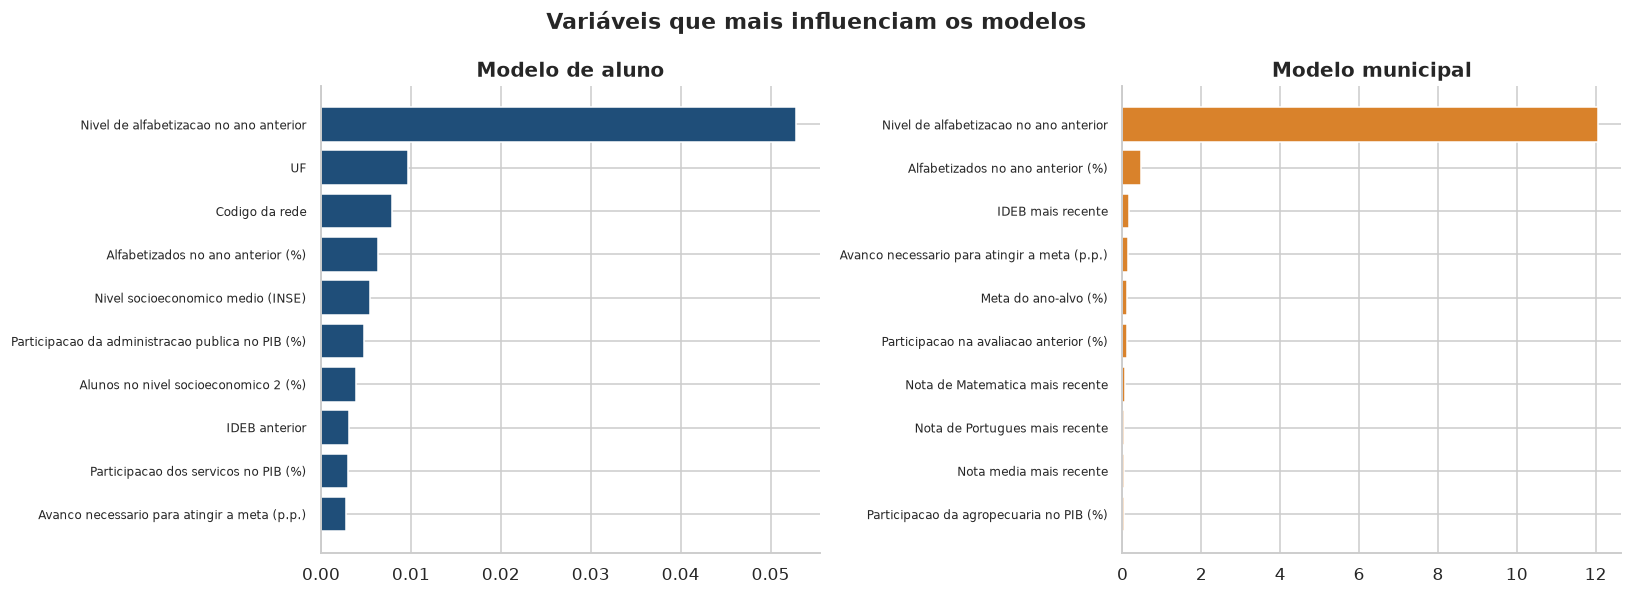

,rotulo,importancia_media
0,Nivel de alfabetizacao no ano anterior,0.0528
1,UF,0.0096
2,Codigo da rede,0.0079
3,Alfabetizados no ano anterior (%),0.0064
4,Nivel socioeconomico medio (INSE),0.0054
5,Participacao da administracao publica no PIB (%),0.0048
6,Alunos no nivel socioeconomico 2 (%),0.0039
7,IDEB anterior,0.0031
8,Participacao dos servicos no PIB (%),0.0030
9,Avanco necessario para atingir a meta (p.p.),0.0028


,rotulo,aumento_erro_medio
0,Nivel de alfabetizacao no ano anterior,12.0498
1,Alfabetizados no ano anterior (%),0.4819
2,IDEB mais recente,0.1642
3,Avanco necessario para atingir a meta (p.p.),0.1323
4,Meta do ano-alvo (%),0.1228
5,Participacao na avaliacao anterior (%),0.1142
6,Nota de Matematica mais recente,0.0578
7,Nota de Portugues mais recente,0.0510
8,Nota media mais recente,0.0488
9,Participacao da agropecuaria no PIB (%),0.0404


In [ ]:
top_aluno=imp_aluno.head(10)[["rotulo","importancia_media"]].copy()
top_mun=imp_mun.head(10)[["rotulo","aumento_erro_medio"]].copy()

fig,axes=plt.subplots(1,2,figsize=(15,5.5))
for ax,df,coluna,titulo,cor in [
    (axes[0],top_aluno,"importancia_media","Modelo de aluno",AZUL),
    (axes[1],top_mun,"aumento_erro_medio","Modelo municipal",LARANJA),
]:
    d=df.sort_values(coluna)
    ax.barh(d["rotulo"],d[coluna],color=cor)
    ax.set_title(titulo)
    ax.tick_params(axis="y",labelsize=8)
fig.suptitle("Variáveis que mais influenciam os modelos",fontweight="bold")
salvar_figura(fig,"09_fatores_principais")
plt.show()

display(top_aluno.round(4))
display(top_mun.round(4))


**Resposta:** a tabela mostra quais variáveis o modelo mais utiliza. A leitura deve distinguir os grãos: no modelo de aluno, a importância representa contribuição para ordenar a chance individual com base em contexto escolar e municipal; no modelo municipal, representa contribuição para reduzir o erro na previsão do percentual alfabetizado.


##### 3. Quais municípios apresentam maior risco educacional?


In [4]:
if ranking.empty:
    print("Ranking de risco indisponível. Execute primeiro o notebook de projeção municipal.")
else:
    coluna_risco=next((c for c in ["risco_nao_atingir","risco_2026","risco"] if c in ranking.columns),None)
    lista_cols=[c for c in ["posicao","nome_municipio","sigla_uf","rede","indicador_t1","meta_t","indicador_previsto","folga_prevista_pp",coluna_risco] if c in ranking.columns]
    display(ranking.sort_values(coluna_risco,ascending=False)[lista_cols].head(25).round(3))
    print(f"Lista completa: {arquivos_risco[-1]}")


,posicao,nome_municipio,sigla_uf,rede,indicador_t1,meta_t,indicador_previsto,folga_prevista_pp,risco_nao_atingir
0,1,Itacurubi,RS,municipal,21.0,80.0,38.320,-41.680,0.998
1,2,Esmeralda,RS,municipal,36.0,80.0,38.638,-41.362,0.998
2,3,Amaral Ferrador,RS,municipal,25.0,75.0,35.671,-39.329,0.998
3,4,Barra do Ribeiro,RS,municipal,38.0,74.0,36.545,-37.455,0.996
4,5,Pedro Osório,RS,municipal,37.0,73.0,36.230,-36.770,0.996
5,6,Santo Antônio das Missões,RS,municipal,40.0,76.0,39.785,-36.215,0.996
6,7,Itatiba do Sul,RS,municipal,47.0,80.0,44.185,-35.815,0.996
7,8,São Sepé,RS,municipal,30.0,80.0,44.403,-35.597,0.995
8,9,Caiçara,RS,municipal,40.0,79.0,44.189,-34.811,0.995
9,10,Chalé,MG,municipal,36.0,80.0,45.392,-34.608,0.995


Lista completa: /home/linux/projetos/Teste_02112026/reports/municipios_risco_2026.csv


**Resposta:** maior risco não significa necessariamente menor indicador atual. O ranking compara o nível previsto com a meta futura; municípios com meta mais exigente podem aparecer acima de municípios com resultado atual menor.


##### 4. Quais territórios possuem padrões semelhantes?


In [5]:
if perfis.empty:
    print("Perfis indisponíveis. Execute os notebooks 06 e 07.")
else:
    display(pd.crosstab(perfis["perfil_municipal"],perfis.get("nome_regiao",pd.Series("não informado",index=perfis.index))))
    display(perfis.groupby("perfil_municipal")["id_municipio"].nunique().sort_values(ascending=False).to_frame("municípios"))


nome_regiao,Centro-Oeste,Nordeste,Norte,Sudeste,Sul
perfil_municipal,,,,,
"Ideb alto, inse alto, menor porte",350,411,85,1355,1077
"Ideb baixo, inse baixo, maior porte",115,1377,347,278,82


,municípios
perfil_municipal,
"Ideb alto, inse alto, menor porte",3278
"Ideb baixo, inse baixo, maior porte",2199


**Resposta:** os padrões semelhantes são definidos pelas condições educacionais, econômicas e territoriais, não apenas pela macrorregião. Municípios de regiões distintas podem pertencer ao mesmo perfil e demandar estratégias semelhantes.


##### 5. Como prever municípios que podem não atingir metas futuras?


In [6]:
backtest=meta_mun.get("backtest") or {}
resposta_backtest=pd.Series({
    "modelo":meta_mun.get("modelo"),
    "alvo modelado":meta_mun.get("alvo_modelado"),
    "MAE":backtest.get("mae"),
    "RMSE":backtest.get("rmse"),
    "R²":backtest.get("r2"),
    "viés":backtest.get("vies"),
    "Spearman":backtest.get("spearman"),
    "ano de backtest":meta_mun.get("ano_backtest"),
})
display(resposta_backtest.to_frame("valor"))


,valor
modelo,random_forest
alvo modelado,indicador_t
MAE,10.406482
RMSE,13.145083
R²,0.341615
viés,-8.500007
Spearman,0.819019
ano de backtest,2025


**Resposta:** o fluxo adotado prevê primeiro o nível do indicador municipal e depois compara esse nível com a meta. O risco é derivado da distribuição dos resíduos de validação. Essa formulação separa o fenômeno educacional da regra administrativa da meta e deve ser reavaliada a cada novo ciclo.


##### 6. Quais variáveis possuem maior influência nos modelos?


In [7]:
influencia=pd.concat({
    "aluno, queda de AUC":imp_aluno.set_index("rotulo")["importancia_media"].head(12),
    "município, aumento do erro":imp_mun.set_index("rotulo")["aumento_erro_medio"].head(12),
},axis=1)
display(influencia.round(4))


,"aluno, queda de AUC","município, aumento do erro"
rotulo,,
Nivel de alfabetizacao no ano anterior,0.0528,12.0498
UF,0.0096,NaN
Codigo da rede,0.0079,NaN
Alfabetizados no ano anterior (%),0.0064,0.4819
Nivel socioeconomico medio (INSE),0.0054,NaN
Participacao da administracao publica no PIB (%),0.0048,NaN
Alunos no nivel socioeconomico 2 (%),0.0039,NaN
IDEB anterior,0.0031,NaN
Participacao dos servicos no PIB (%),0.0030,NaN


**Resposta:** as duas colunas usam escalas diferentes e não devem ser comparadas numericamente entre si. Dentro de cada modelo, valores maiores indicam uma dependência maior da feature.


##### 7. Limitações e recomendação de uso


In [8]:
limites=pd.DataFrame([
    {"tema":"causalidade","registro":"Importância explica o modelo, não o efeito de uma intervenção."},
    {"tema":"modelo do aluno","registro":"As features são majoritariamente contextuais; o uso apropriado é priorizar redes e escolas, não rotular crianças."},
    {"tema":"risco municipal","registro":"O risco é útil para ordenação e triagem; choques entre anos podem deslocar a probabilidade."},
    {"tema":"perfis","registro":"Os segmentos são recortes operacionais de um contínuo e devem ser revistos com novos dados."},
    {"tema":"governança","registro":"Reavaliar métricas, limiar e distribuição das features após cada nova edição."},
])
display(limites)


,tema,registro
0,causalidade,"Importância explica o modelo, não o efeito de ..."
1,modelo do aluno,As features são majoritariamente contextuais; ...
2,risco municipal,O risco é útil para ordenação e triagem; choqu...
3,perfis,Os segmentos são recortes operacionais de um c...
4,governança,"Reavaliar métricas, limiar e distribuição das ..."


#### 8. Entregas geradas

- `reports/importancia_permutacao_aluno.csv`
- `reports/importancia_permutacao_municipio.csv`
- `reports/municipios_risco_<ano>.csv`
- `reports/perfis_municipais_e_prioridades.csv`
- gráficos compactos em `images/`

Esses arquivos sustentam as respostas do Tech Challenge sem repetir treinamento ou análises extensas.


#### Resumo do Notebook 09 · Aplicação Estratégica do Tech Challenge

O notebook consolida os resultados dos modelos, do ranking de risco, dos perfis municipais e da interpretabilidade para responder às perguntas estratégicas do projeto. 

##### Resultados numéricos

##### Modelo municipal no backtest de 2025

| Métrica | Resultado |
|---|---:|
| MAE | **10,4 p.p.** |
| RMSE | **13,1 p.p.** |
| R² | **0,34** |
| Viés | **-8,5 p.p.** |
| Spearman | **0,82** |

O modelo apresenta boa capacidade de ordenar os municípios, indicada pelo Spearman de **0,82**, mas ainda possui erro relevante no nível previsto e tendência de subestimação, indicada pelo viés de **-8,5 p.p.**

##### Análise do gráfico de influência

O gráfico apresenta duas escalas diferentes:

- no **modelo de aluno**, a importância representa a queda da AUC após embaralhar uma variável;
- no **modelo municipal**, representa o aumento do erro absoluto após o embaralhamento.

Por isso, os valores dos dois painéis não devem ser comparados diretamente. 

##### Modelo de aluno

- O **nível de alfabetização no ano anterior** é a variável dominante, com queda de AUC próxima de **0,053**.
- UF aparece em segundo lugar, perto de **0,010**.
- Código da rede e percentual de alfabetizados no ano anterior ficam abaixo de **0,010**.
- INSE e composição econômica aparecem em seguida, mas com impacto individual menor.

O painel indica que o modelo de aluno é principalmente contextual: histórico municipal, UF e rede têm mais influência do que as demais variáveis disponíveis.

##### Modelo municipal

- O **nível de alfabetização no ano anterior** aumenta o erro absoluto em aproximadamente **12 p.p.** quando embaralhado.
- O percentual de alfabetizados no ano anterior aparece em segundo lugar, mas abaixo de **0,5 p.p.**.
- IDEB, avanço necessário, meta, participação anterior, notas, população e região apresentam contribuições muito pequenas na escala do gráfico.

O painel mostra que a previsão municipal depende quase integralmente da trajetória histórica recente. As demais variáveis refinam a previsão, mas não substituem o histórico.

##### Conclusões

- O histórico de alfabetização é o principal sinal nos dois modelos.
- O modelo municipal ordena bem os municípios, mas apresenta erro absoluto e viés relevantes no backtest.
- O modelo de aluno utiliza também UF, rede e contexto socioeconômico, reforçando que sua saída deve apoiar priorização de redes e escolas, não decisões individuais sobre crianças.
- A concentração de importância em uma única variável exige comparação com um baseline simples baseado no resultado anterior.
- Importância por permutação mostra dependência preditiva, não causalidade.
- O uso recomendado é triagem, planejamento e priorização, com revisão humana e atualização do modelo a cada novo ciclo. citeturn111search21

> **Síntese:** o notebook conclui que a persistência histórica domina a previsão da alfabetização. O modelo municipal é útil para ranking e priorização, mas o erro de nível e o viés exigem cautela na leitura dos valores absolutos.
